<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Football League Data](https://github.com/Query-farm/vgi-nfl)

NFL scores, standings, box scores, play-by-play, and player statistics as SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nfl/blob/main/notebooks/02_reconcile_players_before_assigning_teams.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nfl/blob/main/notebooks/README.md)


## Reconcile players before assigning their season totals to teams

A player can change clubs while a season row retains only a recent-team label. Do weekly rows reproduce season totals, and which grain should allocate a traded player’s yards to a club?

**Real public responses, recorded independently on 2026-11-15 UTC.** Default replay serves complete unchanged response bodies through the released worker. The [provenance manifest](recordings/provenance.json) keeps acquisition times, URLs and hashes. These are historical observations, not synthetic data or an atomic snapshot. All analytical transformations stay in visible SQL.

### Choose one local rule

`COHORT` chooses all identified players or players whose directory `rookie_season` is 2025. It changes only the eight displayed player leaders. The fixed 2025 regular-season team audit stays unchanged. This directory property is different from the directory’s acquisition-time latest club.

In [1]:
DATA_MODE = "replay"
COHORT = "all"  # "all" or "rookies"; experiment: "rookies"

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.54":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.54"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nfl")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nfl_examples import NFLExample

if COHORT not in {"all", "rookies"}:
    raise ValueError("COHORT must be all or rookies")
source = NFLExample(DATA_MODE, "totals")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public nflverse responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public nflverse responses · independent reads"
) + " · worker v0.2.0"

### Attach the public release

The short tag command owns dependencies in a separate Python 3.13 worker process. Shared setup starts UTC with empty temporary SQL secrets and persistence disabled. The companion verifies hashes and permits only this scenario's exact requests on loopback; all other upstream roots also point to the rejecting loopback server. Live mode clears inherited root overrides, uses the public endpoints and never falls back to recordings. Restart and run all in a fresh kernel after changing a parameter.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nfl' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nfl@v0.2.0 vgi-nfl');

,Success


### Materialize five sources at their own grain

The weekly asset includes regular and postseason rows; keep that scope visible before selecting `REG`. Player-season and team-season requests explicitly select `REG`. Schedule retrieval includes postseason games, while the player directory spans many seasons. All five **complete assets** are downloaded before the worker applies filters: neither a team argument nor a SQL LIMIT promises a small download.

The directory supplies stable GSIS joins and the rookie-year cohort. Do not use its current `latest_team` for historical attribution. Independent files can be revised on different schedules, so test correspondence rather than assuming it.

In [5]:
%%sql
CREATE TABLE weekly AS SELECT * FROM nfl.main.player_stats_week(season:=2025);
CREATE TABLE player_season AS SELECT * FROM nfl.main.player_stats_season(season:=2025,season_type:='REG');
CREATE TABLE team_season AS SELECT * FROM nfl.main.team_stats(season:=2025,season_type:='REG');
CREATE TABLE schedule AS SELECT * FROM nfl.main.schedule(season:=2025);
CREATE TABLE directory AS SELECT * FROM nfl.main.players;

,Count


In [6]:
%%sql source_scope <<
SELECT 'Weekly REG rows' AS population,count(*) AS rows,
 count(*) FILTER(WHERE player_id IS NULL) AS missing_player_id FROM weekly WHERE season_type='REG'
UNION ALL SELECT 'Weekly POST rows',count(*),count(*) FILTER(WHERE player_id IS NULL) FROM weekly WHERE season_type='POST'
UNION ALL SELECT 'Player-season REG rows',count(*),count(*) FILTER(WHERE player_id IS NULL) FROM player_season
UNION ALL SELECT 'Player directory',count(*),count(*) FILTER(WHERE gsis_id IS NULL) FROM directory
ORDER BY population;

In [7]:
display(source_scope)
prose(
    "The missing-ID rows are retained in this source audit. They are **not identifiable players** and will not be joined or counted as a player. The checks below verify that their selected offensive counts are zero in this acquisition; this does not explain why the provider emitted them or authorize inventing an identity."
)

,population,rows,missing_player_id
0,Player directory,24869,0
1,Player-season REG rows,2020,1
2,Weekly POST rows,882,4
3,Weekly REG rows,18540,18


The missing-ID rows are retained in this source audit. They are **not identifiable players** and will not be joined or counted as a player. The checks below verify that their selected offensive counts are zero in this acquisition; this does not explain why the provider emitted them or authorize inventing an identity.

### Reconcile identifiable players, then preserve weekly team allocation

Group weekly `REG` rows by non-null player ID and compare six additive counts with the season report. Separately group those weekly rows by the team recorded **in that game**, then reconcile rushing and gross passing/receiving yards to the team report. The schedule supplies each team’s completed regular-season game denominator.

The deliberately naive comparison assigns an entire player-season total to `recent_team`. Its difference from weekly allocation demonstrates an attribution error, not an error in the underlying season count. Yardage from scrimmage means rushing plus receiving yards; passing yards are not added again.

In [8]:
%%sql
CREATE TABLE regular_weekly AS
SELECT * FROM weekly WHERE season_type='REG' AND player_id IS NOT NULL;
CREATE TABLE weekly_players AS
SELECT player_id,sum(attempts) AS attempts,sum(passing_yards) AS passing_yards,
 sum(carries) AS carries,sum(rushing_yards) AS rushing_yards,
 sum(receptions) AS receptions,sum(receiving_yards) AS receiving_yards
FROM regular_weekly GROUP BY player_id;
CREATE TABLE player_reconciliation AS
SELECT coalesce(w.player_id,s.player_id) AS player_id,
 w.player_id IS NOT NULL AND s.player_id IS NOT NULL AS both_present,
 coalesce(w.attempts=s.attempts AND w.passing_yards=s.passing_yards
  AND w.carries=s.carries AND w.rushing_yards=s.rushing_yards
  AND w.receptions=s.receptions AND w.receiving_yards=s.receiving_yards,false) AS counts_agree
FROM weekly_players w FULL JOIN (SELECT * FROM player_season WHERE player_id IS NOT NULL) s USING(player_id);
CREATE TABLE games_by_team AS
SELECT team,count(*) AS completed_games FROM (
 SELECT home_team AS team FROM schedule WHERE game_type='REG' AND home_score IS NOT NULL AND away_score IS NOT NULL
 UNION ALL SELECT away_team FROM schedule WHERE game_type='REG' AND home_score IS NOT NULL AND away_score IS NOT NULL
) GROUP BY team;
CREATE TABLE weekly_teams AS
SELECT team,sum(passing_yards) AS passing_yards,sum(rushing_yards) AS rushing_yards,
 sum(receiving_yards) AS receiving_yards,sum(carries) AS carries,
 sum(rushing_yards+receiving_yards) AS allocated_scrimmage_yards
FROM regular_weekly GROUP BY team;
CREATE TABLE recent_team_allocation AS
SELECT recent_team AS team,sum(rushing_yards+receiving_yards) AS assigned_scrimmage_yards
FROM player_season WHERE player_id IS NOT NULL GROUP BY recent_team;
CREATE TABLE team_audit AS
SELECT w.team,g.completed_games,t.games AS reported_games,
 w.allocated_scrimmage_yards,t.rushing_yards+t.passing_yards AS reported_gross_scrimmage,
 w.passing_yards=t.passing_yards AND w.rushing_yards=t.rushing_yards
  AND w.carries=t.carries AND w.receiving_yards=t.passing_yards AS counts_agree,
 r.assigned_scrimmage_yards,
 1.0*w.allocated_scrimmage_yards/g.completed_games AS allocated_yards_per_game,
 1.0*r.assigned_scrimmage_yards/g.completed_games AS recent_team_yards_per_game
FROM weekly_teams w FULL JOIN team_season t USING(team)
FULL JOIN games_by_team g USING(team) FULL JOIN recent_team_allocation r USING(team);
CREATE TABLE annotated_players AS
SELECT s.player_id,s.player_display_name,s.recent_team,p.rookie_season,
 s.rushing_yards+s.receiving_yards AS scrimmage_yards,s.carries+s.receptions AS touches
FROM player_season s LEFT JOIN directory p ON s.player_id=p.gsis_id
WHERE s.player_id IS NOT NULL;

,Count


In [9]:
%%sql attribution <<
SELECT *,recent_team_yards_per_game-allocated_yards_per_game AS attribution_difference
FROM team_audit ORDER BY abs(attribution_difference) DESC,team;

,team,completed_games,reported_games,allocated_scrimmage_yards,reported_gross_scrimmage,counts_agree,assigned_scrimmage_yards,allocated_yards_per_game,recent_team_yards_per_game,attribution_difference
0,NO,17,17,5630.0,5630,True,4962.0,331.176471,291.882353,-39.294118
1,SEA,17,17,6159.0,6159,True,6682.0,362.294118,393.058824,30.764706
2,JAX,17,17,5982.0,5982,True,6322.0,351.882353,371.882353,20.000000
3,LV,17,17,4632.0,4632,True,4350.0,272.470588,255.882353,-16.588235
4,NYJ,17,17,4880.0,4880,True,5050.0,287.058824,297.058824,10.000000
5,BUF,17,17,6695.0,6695,True,6860.0,393.823529,403.529412,9.705882
6,IND,17,17,6092.0,6092,True,5940.0,358.352941,349.411765,-8.941176
7,PIT,17,17,5388.0,5388,True,5497.0,316.941176,323.352941,6.411765
8,MIN,17,17,5049.0,5049,True,4961.0,297.000000,291.823529,-5.176471
9,TEN,17,17,4830.0,4830,True,4760.0,284.117647,280.000000,-4.117647


All **32 teams** retain the schedule-derived game denominator. **22 teams** change when whole player seasons are assigned to a recent club. The largest displayed difference is **NO: -39.3 yards per game**. Weekly allocation and the team report reconcile; the recent-club calculation is intentionally shown as the wrong historical allocation.

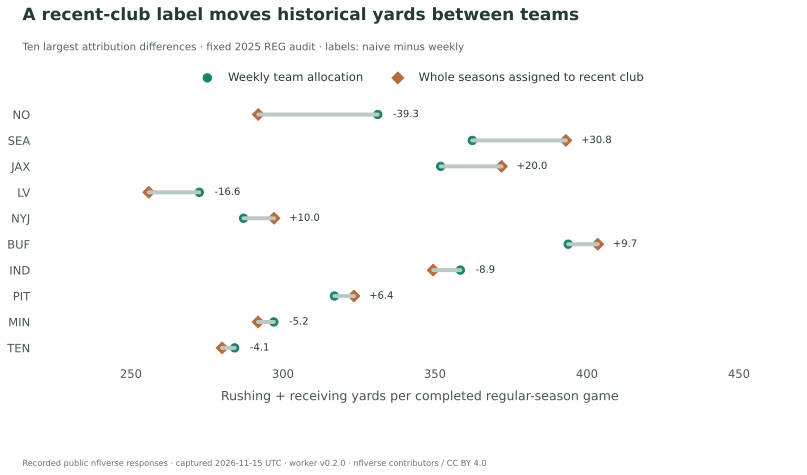

In [10]:
display(attribution.head(10))
changed = int((attribution.attribution_difference.abs() > 1e-10).sum())
prose(
    f"All **{len(attribution)} teams** retain the schedule-derived game denominator. **{changed} teams** change when whole player seasons are assigned to a recent club. The largest displayed difference is **{attribution.iloc[0].team}: {attribution.iloc[0].attribution_difference:+.1f} yards per game**. Weekly allocation and the team report reconcile; the recent-club calculation is intentionally shown as the wrong historical allocation."
)
rows = attribution.head(10)
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(rows))
ax.plot(
    np.vstack([rows.allocated_yards_per_game, rows.recent_team_yards_per_game]),
    np.vstack([y, y]),
    color="#bbc9c2",
    linewidth=4,
)
ax.scatter(rows.allocated_yards_per_game, y, s=70, color="#16836e", label="Weekly team allocation")
ax.scatter(
    rows.recent_team_yards_per_game,
    y,
    s=70,
    color="#b66d3e",
    marker="D",
    label="Whole seasons assigned to recent club",
)
for i, r in enumerate(rows.itertuples()):
    ax.text(
        max(r.allocated_yards_per_game, r.recent_team_yards_per_game) + 5,
        i,
        f"{r.attribution_difference:+.1f}",
        va="center",
        fontsize=10,
    )
ax.set_yticks(y, rows.team)
ax.invert_yaxis()
ax.set_xlim(220, 470)
ax.set_xlabel("Rushing + receiving yards per completed regular-season game")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.16), frameon=False, ncol=2)
finish(
    fig,
    title="A recent-club label moves historical yards between teams",
    subtitle="Ten largest attribution differences · fixed 2025 REG audit · labels: naive minus weekly",
    source=SOURCE + " · nflverse contributors / CC BY 4.0",
    name="team-attribution",
)

### Change the player comparison pool without changing attribution

The next ranking uses the reconciled **player-season** totals. The directory’s rookie year selects a cohort on a one-to-one GSIS join. A rookie-only list is a different comparison population, not an adjustment for age, position, opportunity, quality or future potential. Touches are carries plus receptions; they are not snaps or targets.

In [11]:
%%sql leaders <<
SELECT * FROM annotated_players
WHERE '{{COHORT}}'='all' OR rookie_season=2025
ORDER BY scrimmage_yards DESC,player_id LIMIT 8;

In [12]:
%%sql cohort_scope <<
SELECT count(*) AS identified_players,count(*) FILTER(WHERE rookie_season IS NULL) AS missing_rookie_year,
 count(*) FILTER(WHERE '{{COHORT}}'='all' OR rookie_season=2025) AS selected_players,
 (SELECT count(*) FROM player_reconciliation WHERE both_present AND counts_agree) AS reconciled_players
FROM annotated_players;

,identified_players,missing_rookie_year,selected_players,reconciled_players
0,2019,0,2019,2019


,player_id,player_display_name,recent_team,rookie_season,scrimmage_yards,touches
0,00-0038542,Bijan Robinson,ATL,2023,2298,366
1,00-0033280,Christian McCaffrey,SF,2017,2126,413
2,00-0036223,Jonathan Taylor,IND,2020,1963,369
3,00-0037248,James Cook,BUF,2022,1912,342
4,00-0039139,Jahmyr Gibbs,DET,2023,1839,320
5,00-0039040,De'Von Achane,MIA,2023,1838,305
6,00-0038543,Jaxon Smith-Njigba,SEA,2023,1829,126
7,00-0039075,Puka Nacua,LA,2023,1820,139


The six count fields reconcile for **2,019 identifiable players**. Cohort **all** contains **2,019 players**, with **8 displayed**. The first is **Bijan Robinson**, with **2,298 yards on 366 touches**. This list retains player totals; the recent-team label is context, not an allocation of those yards.

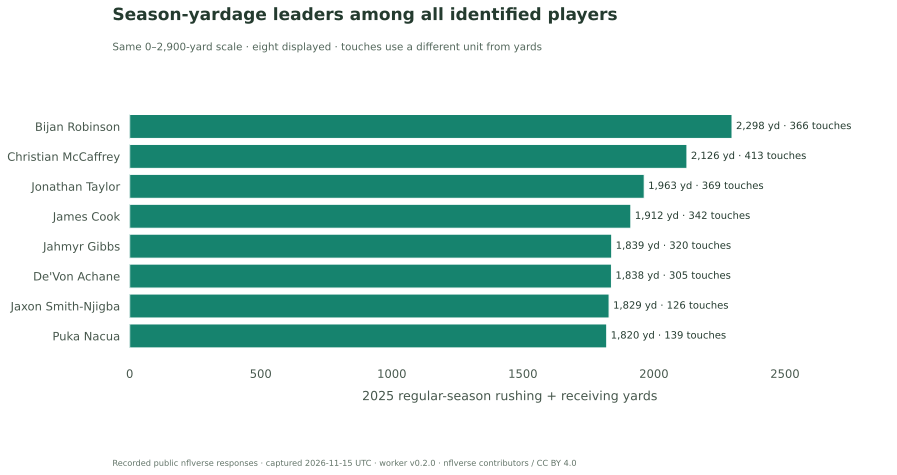

In [13]:
display(cohort_scope)
display(leaders)
r = cohort_scope.iloc[0]
prose(
    f"The six count fields reconcile for **{int(r.reconciled_players):,} identifiable players**. Cohort **{COHORT}** contains **{int(r.selected_players):,} players**, with **{len(leaders)} displayed**. The first is **{leaders.iloc[0].player_display_name}**, with **{int(leaders.iloc[0].scrimmage_yards):,} yards on {int(leaders.iloc[0].touches)} touches**. This list retains player totals; the recent-team label is context, not an allocation of those yards."
)
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(leaders.player_display_name, leaders.scrimmage_yards, color="#16836e")
ax.bar_label(
    bars,
    labels=[f"{int(r.scrimmage_yards):,} yd · {int(r.touches)} touches" for r in leaders.itertuples()],
    padding=4,
    fontsize=10,
)
ax.invert_yaxis()
ax.set_xlim(0, 2900)
ax.set_xlabel("2025 regular-season rushing + receiving yards")
finish(
    fig,
    title="Season-yardage leaders among " + ("all identified players" if COHORT == "all" else "2025 rookies"),
    subtitle="Same 0–2,900-yard scale · eight displayed · touches use a different unit from yards",
    source=SOURCE + " · nflverse contributors / CC BY 4.0",
    name=f"player-cohort-{COHORT}",
)

In [14]:
%%sql checks <<
SELECT 'Source regular season retained' AS check_name,bool_and(season=2025 AND season_type='REG') AS passed FROM player_season
UNION ALL SELECT 'Weekly keyed rows unique',(SELECT count(*)=count(DISTINCT (player_id,week,team)) FROM regular_weekly)
UNION ALL SELECT 'Null-ID offensive counts zero',coalesce(bool_and(attempts=0 AND passing_yards=0 AND carries=0 AND rushing_yards=0 AND receptions=0 AND receiving_yards=0),true) FROM weekly WHERE player_id IS NULL
UNION ALL SELECT 'Null season counts zero',coalesce(bool_and(attempts=0 AND passing_yards=0 AND carries=0 AND rushing_yards=0 AND receptions=0 AND receiving_yards=0),true) FROM player_season WHERE player_id IS NULL
UNION ALL SELECT 'Player-season keys unique',count(*)=count(DISTINCT player_id) FROM player_season WHERE player_id IS NOT NULL
UNION ALL SELECT 'Directory keys unique',count(*)=count(DISTINCT gsis_id) FROM directory
UNION ALL SELECT 'Every identified player reconciles',bool_and(both_present AND counts_agree) FROM player_reconciliation
UNION ALL SELECT 'Directory join does not multiply',count(*)=(SELECT count(*) FROM player_season WHERE player_id IS NOT NULL) FROM annotated_players
UNION ALL SELECT 'Directory rookie-year coverage',count(*) FILTER(WHERE rookie_season IS NULL)=0 FROM annotated_players
UNION ALL SELECT 'All team grains present',count(*)=32 AND count(DISTINCT team)=32 AND bool_and(counts_agree) FROM team_audit
UNION ALL SELECT 'Schedule and team game counts agree',bool_and(completed_games=reported_games AND completed_games=17) FROM team_audit
UNION ALL SELECT 'Weekly allocation matches gross team yardage',bool_and(allocated_scrimmage_yards=reported_gross_scrimmage) FROM team_audit
UNION ALL SELECT 'Naive assignment conserves league total',sum(allocated_scrimmage_yards)=sum(assigned_scrimmage_yards) FROM team_audit
UNION ALL SELECT 'Recent-team error is observable',count(*) FILTER(WHERE assigned_scrimmage_yards<>allocated_scrimmage_yards)>0 FROM team_audit
UNION ALL SELECT 'Rookie cohort is nonempty',count(*)>0 FROM annotated_players WHERE rookie_season=2025;

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "parameters": {"DATA_MODE": DATA_MODE, "COHORT": COHORT},
            "source_scope": source_scope.to_dict("records"),
            "attribution": attribution.to_dict("records"),
            "leaders": leaders.to_dict("records"),
            "cohort_scope": cohort_scope.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,Source regular season retained,True
1,Weekly keyed rows unique,True
2,Null-ID offensive counts zero,True
3,Null season counts zero,True
4,Player-season keys unique,True
5,Directory keys unique,True
6,Every identified player reconciles,True
7,Directory join does not multiply,True
8,Directory rookie-year coverage,True
9,All team grains present,True


**All 15 SQL checks passed.** Exactly 5 recorded responses requested once each; no unexpected requests.

16503

### Change one thing

Change only `COHORT` from `"all"` to `"rookies"`. Predict that the eight displayed names and yard totals will change, while every weekly/season reconciliation and the team-attribution figure remain identical. Compare the player counts and leading row. Restore `"all"` afterwards. The experiment changes the comparison pool; it does not reassign any source event or estimate player quality.

In [16]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nfl](https://github.com/Query-farm/vgi-nfl)